# DukaanAI EDA

This notebook performs exploratory data analysis for the retail inventory dataset, including cleaning, validation, trend analysis, and export-ready outputs.


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Consistent graph style
sns.set_theme(style="whitegrid")

# Load data if this notebook is opened directly
if "df" not in globals():
    candidates = [
        "retail_store_inventory.csv",
        os.path.join("..", "data", "raw", "retail_store_inventory.csv"),
        os.path.join("data", "raw", "retail_store_inventory.csv"),
    ]
    data_path = next((path for path in candidates if os.path.exists(path)), None)
    if data_path is None:
        raise FileNotFoundError("Dataset not found in expected locations")
    df = pd.read_csv(data_path)

# Work on a copy so the original DataFrame remains unchanged
eda_df = df.copy()

# Remove extra spaces from column names
eda_df.columns = eda_df.columns.str.strip()

# Columns required for this analysis
required_cols = [
    "Date", "Store ID", "Product ID", "Category", "Region",
    "Inventory Level", "Units Sold", "Units Ordered",
    "Demand Forecast", "Price", "Discount",
    "Weather Condition", "Holiday/Promotion",
    "Competitor Pricing", "Seasonality"
]

# Stop if any required column is missing
missing_columns = [
    col for col in required_cols
    if col not in eda_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Keep the expected columns in a consistent order
eda_df = eda_df[required_cols].copy()

print("=" * 65)
print("DUKAANAI: INITIAL DATASET REPORT")
print("=" * 65)

print("Dataset shape:", eda_df.shape)
print("Number of rows:", len(eda_df))
print("Number of columns:", len(eda_df.columns))

print("\nColumn names:")
print(eda_df.columns.tolist())

print("\nData types:")
print(eda_df.dtypes)


DUKAANAI: INITIAL DATASET REPORT
Dataset shape: (73100, 15)
Number of rows: 73100
Number of columns: 15

Column names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']

Data types:
Date                      str
Store ID                  str
Product ID                str
Category                  str
Region                    str
Inventory Level         int64
Units Sold              int64
Units Ordered           int64
Demand Forecast       float64
Price                 float64
Discount                int64
Weather Condition         str
Holiday/Promotion       int64
Competitor Pricing    float64
Seasonality               str
dtype: object


In [3]:
print("\n" + "=" * 65)
print("SECTION 2: MISSING VALUES AND DUPLICATES")
print("=" * 65)

# 2.1 Count missing values before cleaning
print("\nMissing values BEFORE cleaning:")
missing_before = eda_df.isna().sum()
display(missing_before.to_frame("Missing Values"))

# 2.2 Find exact duplicate rows
exact_duplicates = eda_df.duplicated().sum()
print("\nExact duplicate rows:", exact_duplicates)

# Remove exact duplicate rows, assuming they are redundant
eda_df = eda_df.drop_duplicates().copy()

print("Rows after removing exact duplicates:", len(eda_df))

# 2.3 Convert Date into datetime format
eda_df["Date"] = pd.to_datetime(
    eda_df["Date"],
    errors="coerce"
)

invalid_dates = eda_df["Date"].isna().sum()
print("\nInvalid or missing dates:", invalid_dates)

eda_df = eda_df.dropna(subset=["Date"]).copy()

numeric_cols = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "Price",
    "Discount",
    "Holiday/Promotion",
    "Competitor Pricing"
]

for col in numeric_cols:
    eda_df[col] = pd.to_numeric(
        eda_df[col],
        errors="coerce"
    )

print("\nMissing/invalid numerical values after conversion:")
display(
    eda_df[numeric_cols]
    .isna()
    .sum()
    .to_frame("Missing or Invalid Values")
)

non_negative_cols = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "Price",
    "Discount",
    "Competitor Pricing"
]

print("\nNegative values BEFORE correction:")
display(
    eda_df[non_negative_cols]
    .lt(0)
    .sum()
    .to_frame("Negative Values")
)

for col in non_negative_cols:
    eda_df.loc[eda_df[col] < 0, col] = np.nan

invalid_promotion = (
    eda_df["Holiday/Promotion"].notna()
    & ~eda_df["Holiday/Promotion"].isin([0, 1])
)

print(
    "\nInvalid Holiday/Promotion values:",
    invalid_promotion.sum()
)

eda_df.loc[invalid_promotion, "Holiday/Promotion"] = np.nan

eda_df = eda_df.dropna(
    subset=["Store ID", "Product ID"]
).copy()

descriptive_cols = [
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]

for col in descriptive_cols:
    if eda_df[col].isna().any():
        modes = eda_df[col].mode(dropna=True)

        if not modes.empty:
            eda_df[col] = eda_df[col].fillna(modes.iloc[0])

for col in numeric_cols:
    if eda_df[col].isna().any():
        median_value = eda_df[col].median()

        if pd.notna(median_value):
            eda_df[col] = eda_df[col].fillna(median_value)

for col in descriptive_cols:
    eda_df[col] = eda_df[col].fillna("Unknown")

print("\nMissing values AFTER cleaning:")
display(
    eda_df.isna()
    .sum()
    .to_frame("Remaining Missing Values")
)

print("\nDataset shape after cleaning:", eda_df.shape)



SECTION 2: MISSING VALUES AND DUPLICATES

Missing values BEFORE cleaning:


,Missing Values
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0



Exact duplicate rows: 0
Rows after removing exact duplicates: 73100

Invalid or missing dates: 0

Missing/invalid numerical values after conversion:


,Missing or Invalid Values
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0
Discount,0
Holiday/Promotion,0
Competitor Pricing,0



Negative values BEFORE correction:


,Negative Values
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,673
Price,0
Discount,0
Competitor Pricing,0



Invalid Holiday/Promotion values: 0

Missing values AFTER cleaning:


,Remaining Missing Values
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0



Dataset shape after cleaning: (73100, 15)


In [4]:
print("\n" + "=" * 65)
print("SECTION 3: DATA VALIDATION")
print("=" * 65)

print("\nDate range:")
print("Start date:", eda_df["Date"].min())
print("End date:", eda_df["Date"].max())

print("\nNumerical summary:")
display(eda_df[numeric_cols].describe().T)

print("\nNegative values AFTER cleaning:")
display(
    eda_df[non_negative_cols]
    .lt(0)
    .sum()
    .to_frame("Negative Values")
)

print(
    "\nInvalid promotion values AFTER cleaning:",
    (
        eda_df["Holiday/Promotion"].notna()
        & ~eda_df["Holiday/Promotion"].isin([0, 1])
    ).sum()
)

key_cols = ["Date", "Store ID", "Product ID"]
duplicate_keys = eda_df.duplicated(
    subset=key_cols,
    keep=False
)

print(
    "\nRows involved in repeated Date-Store-Product keys:",
    duplicate_keys.sum()
)

if duplicate_keys.any():
    print("\nExample repeated keys to investigate:")
    display(
        eda_df.loc[duplicate_keys]
        .sort_values(key_cols)
        .head(20)
    )

rows_per_date = eda_df.groupby("Date").size()

print("\nMinimum rows per date:", rows_per_date.min())
print("Maximum rows per date:", rows_per_date.max())
print("Unique stores:", eda_df["Store ID"].nunique())
print("Unique products:", eda_df["Product ID"].nunique())

unique_store_product_pairs = (
    eda_df[["Store ID", "Product ID"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Unique store-product combinations:",
    unique_store_product_pairs
)

expected_combinations = (
    eda_df["Store ID"].nunique()
    * eda_df["Product ID"].nunique()
)

print(
    "Expected rows per date if the grid is complete:",
    expected_combinations
)

all_dates = pd.date_range(
    start=eda_df["Date"].min(),
    end=eda_df["Date"].max(),
    freq="D"
)

missing_dates = all_dates.difference(
    pd.DatetimeIndex(eda_df["Date"].unique())
)

print("\nDates with no records:", len(missing_dates))

if len(missing_dates) > 0:
    print("Example missing dates:", missing_dates[:10].tolist())



SECTION 3: DATA VALIDATION

Date range:
Start date: 2022-01-01 00:00:00
End date: 2024-01-01 00:00:00

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Inventory Level,73100.0,274.469877,129.949514,50.00,162.00,273.00,387.0000,500.00
Units Sold,73100.0,136.464870,108.919406,0.00,49.00,107.00,203.0000,499.00
Units Ordered,73100.0,110.004473,52.277448,20.00,65.00,110.00,155.0000,200.00
Demand Forecast,73100.0,142.582418,108.387595,0.01,55.48,114.45,208.0525,518.55
Price,73100.0,55.135108,26.021945,10.00,32.65,55.05,77.8600,100.00
Discount,73100.0,10.009508,7.083746,0.00,5.00,10.00,15.0000,20.00
Holiday/Promotion,73100.0,0.497305,0.499996,0.00,0.00,0.00,1.0000,1.00
Competitor Pricing,73100.0,55.146077,26.191408,5.03,32.68,55.01,77.8200,104.94



Negative values AFTER cleaning:


,Negative Values
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0
Discount,0
Competitor Pricing,0



Invalid promotion values AFTER cleaning: 0

Rows involved in repeated Date-Store-Product keys: 0

Minimum rows per date: 100
Maximum rows per date: 100
Unique stores: 5
Unique products: 20
Unique store-product combinations: 100
Expected rows per date if the grid is complete: 100

Dates with no records: 0


In [6]:
print("\n" + "=" * 65)
print("SECTION 4: CHRONOLOGICAL DATA SPLIT")
print("=" * 65)

eda_df = eda_df.sort_values(
    ["Date", "Store ID", "Product ID"]
).reset_index(drop=True)

unique_dates = np.sort(
    eda_df["Date"].dropna().unique()
)

n_dates = len(unique_dates)

if n_dates < 3:
    raise ValueError(
        "Not enough unique dates for a chronological split."
    )

train_end = int(n_dates * 0.70)
validation_end = int(n_dates * 0.85)

train_dates = unique_dates[:train_end]
validation_dates = unique_dates[train_end:validation_end]
test_dates = unique_dates[validation_end:]

train_df = eda_df[
    eda_df["Date"].isin(train_dates)
].copy()

validation_df = eda_df[
    eda_df["Date"].isin(validation_dates)
].copy()

test_df = eda_df[
    eda_df["Date"].isin(test_dates)
].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Testing rows:", len(test_df))

print("\nTraining period:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nValidation period:")
print(
    validation_df["Date"].min(),
    "to",
    validation_df["Date"].max()
)

print("\nTesting period:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

assert train_df["Date"].max() < validation_df["Date"].min()
assert validation_df["Date"].max() < test_df["Date"].min()

print("\nChronological split verified: no date overlap.")

# Save your splits so another notebook can read them
train_df.to_csv('train_split.csv', index=False)
validation_df.to_csv('val_split.csv', index=False)
test_df.to_csv('test_split.csv', index=False)
print("Splits saved successfully!")



SECTION 4: CHRONOLOGICAL DATA SPLIT
Training rows: 51100
Validation rows: 11000
Testing rows: 11000

Training period:
2022-01-01 00:00:00 to 2023-05-26 00:00:00

Validation period:
2023-05-27 00:00:00 to 2023-09-13 00:00:00

Testing period:
2023-09-14 00:00:00 to 2024-01-01 00:00:00

Chronological split verified: no date overlap.
Splits saved successfully!



SECTION 5: DAILY AND WEEKLY SALES TRENDS


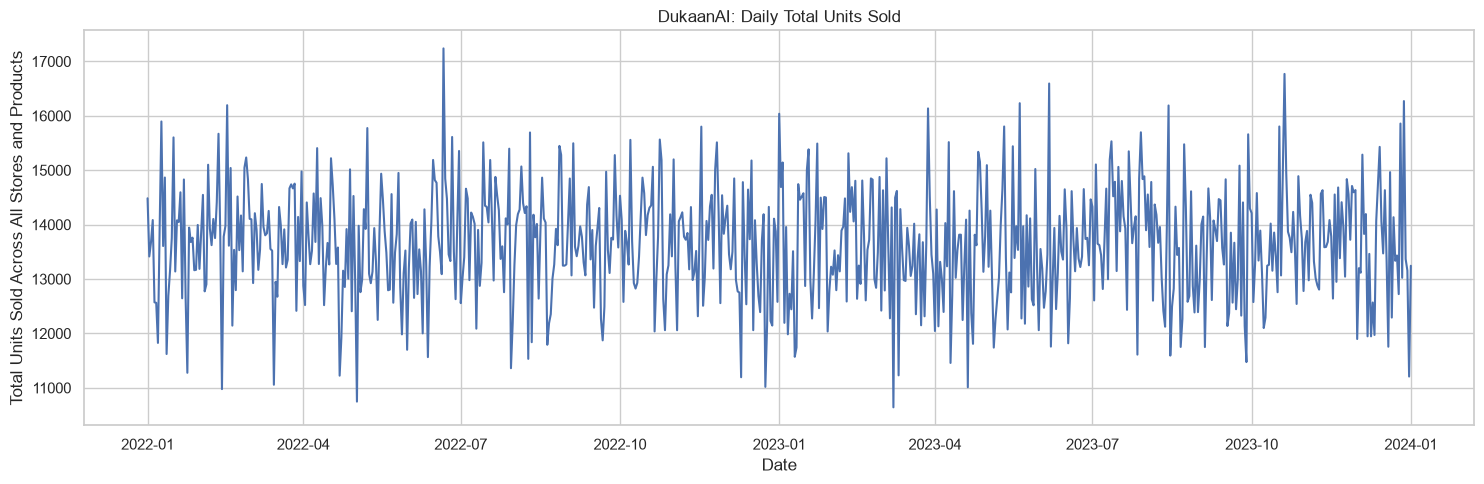

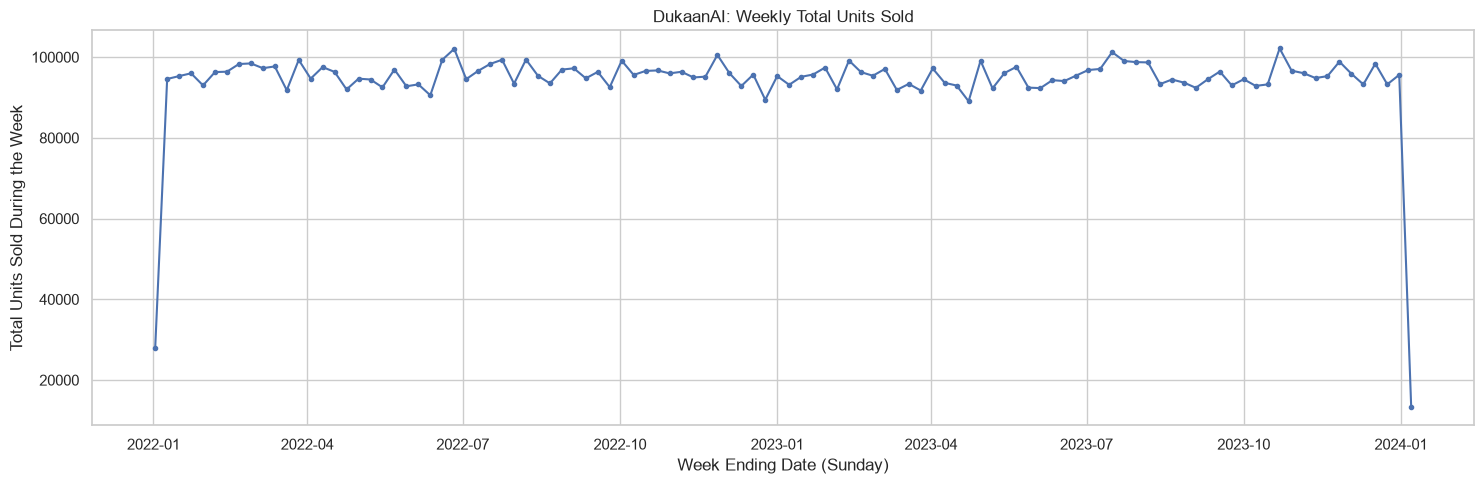


Daily sales summary:


,Daily Units Sold
count,731.000000
mean,13646.487004
std,1031.958966
min,10642.000000
25%,12981.000000
50%,13673.000000
75%,14323.500000
max,17239.000000



Highest-sales dates:


,Total Units Sold
Date,
2022-06-21,17239.0
2023-10-20,16770.0
2023-06-06,16594.0
2023-12-28,16271.0
2023-05-20,16232.0
2022-02-16,16195.0
2023-08-14,16190.0
2023-03-28,16136.0
2023-01-01,16038.0



Lowest-sales dates:


,Total Units Sold
Date,
2023-03-08,10642.0
2022-05-02,10747.0
2022-02-13,10977.0
2023-04-20,11011.0
2022-12-24,11018.0
2022-03-15,11057.0
2022-12-10,11195.0
2023-12-31,11208.0
2022-04-22,11224.0


In [8]:
print("\n" + "=" * 65)
print("SECTION 5: DAILY AND WEEKLY SALES TRENDS")
print("=" * 65)

daily_sales = (
    eda_df.groupby("Date")["Units Sold"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(15, 5))
plt.plot(
    daily_sales.index,
    daily_sales.values,
    linewidth=1.5
)

plt.title("DukaanAI: Daily Total Units Sold")
plt.xlabel("Date")
plt.ylabel("Total Units Sold Across All Stores and Products")

plt.tight_layout()
plt.show()

weekly_sales = daily_sales.resample("W-SUN").sum()
plt.figure(figsize=(15, 5))
plt.plot(
    weekly_sales.index,
    weekly_sales.values,
    marker="o",
    markersize=3
)

plt.title("DukaanAI: Weekly Total Units Sold")
plt.xlabel("Week Ending Date (Sunday)")
plt.ylabel("Total Units Sold During the Week")

plt.tight_layout()
plt.show()

print("\nDaily sales summary:")
display(
    daily_sales.describe()
    .to_frame("Daily Units Sold")
)

print("\nHighest-sales dates:")
display(
    daily_sales.sort_values(ascending=False)
    .head(10)
    .to_frame("Total Units Sold")
)

print("\nLowest-sales dates:")
display(
    daily_sales.sort_values(ascending=True)
    .head(10)
    .to_frame("Total Units Sold")
)



SECTION 6: SALES COMPARISONS

Sales by category:


,count,mean,median,sum
Category,,,,
Furniture,14699,137.765630,109.0,2025017.0
Groceries,14611,136.916159,108.0,2000482.0
Clothing,14626,136.685765,108.0,1999166.0
Toys,14643,135.934235,108.0,1990485.0
Electronics,14521,135.006680,105.0,1960432.0


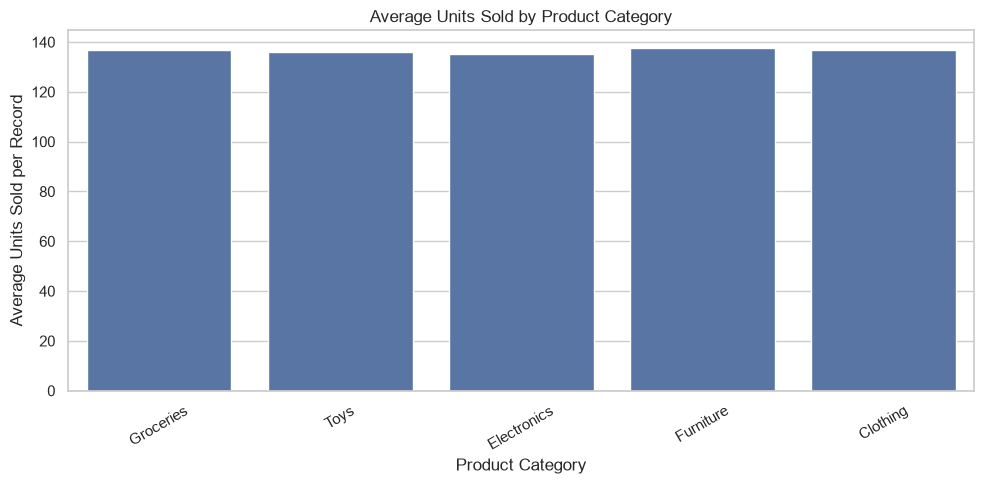


Sales by product:


,count,mean,median,sum
Product ID,,,,
P0016,3655,139.116826,112.0,508472.0
P0020,3655,138.907798,111.0,507708.0
P0014,3655,138.884268,111.0,507622.0
P0015,3655,138.791518,109.0,507283.0
P0005,3655,137.796990,111.0,503648.0
P0009,3655,137.369631,109.0,502086.0
P0013,3655,136.968263,108.0,500619.0
P0017,3655,136.938440,108.0,500510.0
P0011,3655,136.624350,110.0,499362.0


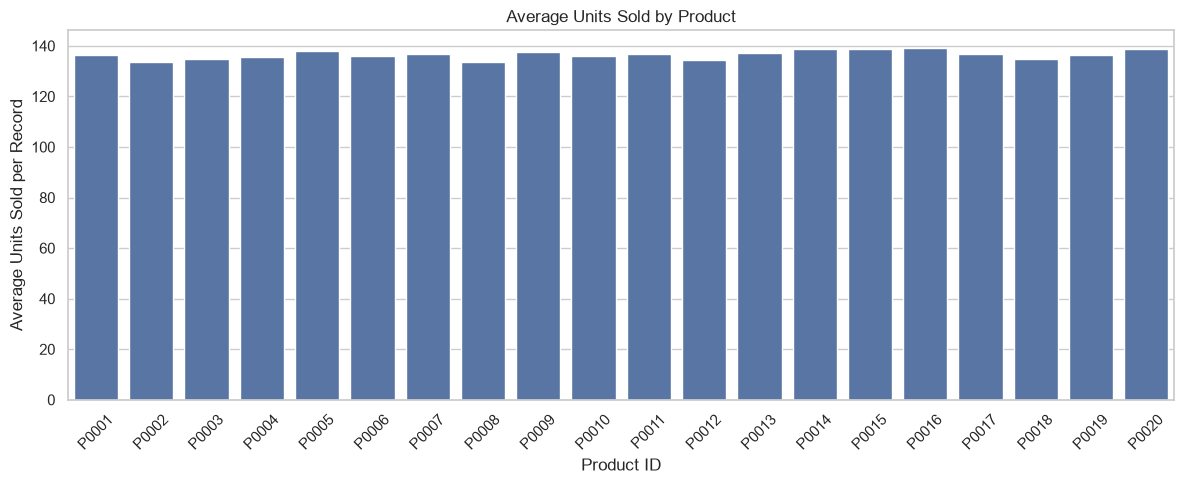


Sales by store:


,count,mean,median,sum
Store ID,,,,
S003,14620,138.351300,110.0,2022696.0
S005,14620,137.494938,108.0,2010176.0
S002,14620,135.958618,105.0,1987715.0
S004,14620,135.379275,108.0,1979245.0
S001,14620,135.140219,106.0,1975750.0


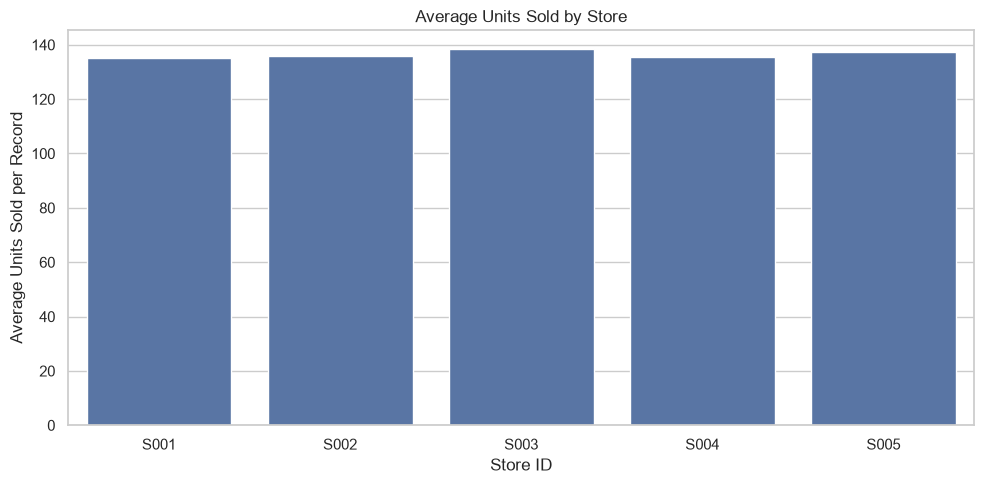

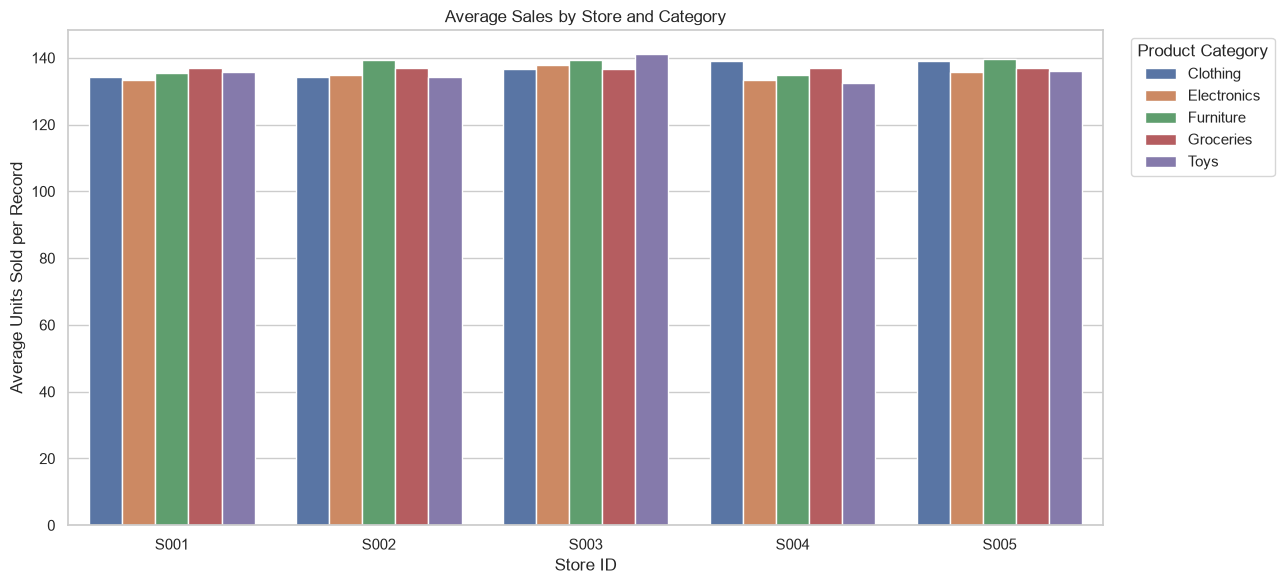

In [9]:
print("\n" + "=" * 65)
print("SECTION 6: SALES COMPARISONS")
print("=" * 65)

category_sales = (
    eda_df.groupby("Category")["Units Sold"]
    .agg(["count", "mean", "median", "sum"])
    .sort_values("sum", ascending=False)
)

print("\nSales by category:")
display(category_sales)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=eda_df,
    x="Category",
    y="Units Sold",
    estimator=np.mean,
    errorbar=None
)
plt.title("Average Units Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Units Sold per Record")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

product_sales = (
    eda_df.groupby("Product ID")["Units Sold"]
    .agg(["count", "mean", "median", "sum"])
    .sort_values("sum", ascending=False)
)

print("\nSales by product:")
display(product_sales)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=eda_df,
    x="Product ID",
    y="Units Sold",
    estimator=np.mean,
    errorbar=None
)
plt.title("Average Units Sold by Product")
plt.xlabel("Product ID")
plt.ylabel("Average Units Sold per Record")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

store_sales = (
    eda_df.groupby("Store ID")["Units Sold"]
    .agg(["count", "mean", "median", "sum"])
    .sort_values("sum", ascending=False)
)

print("\nSales by store:")
display(store_sales)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=eda_df,
    x="Store ID",
    y="Units Sold",
    estimator=np.mean,
    errorbar=None
)
plt.title("Average Units Sold by Store")
plt.xlabel("Store ID")
plt.ylabel("Average Units Sold per Record")
plt.tight_layout()
plt.show()

store_category_sales = (
    eda_df.groupby(["Store ID", "Category"])["Units Sold"]
    .mean()
    .reset_index(name="Average Units Sold")
)

plt.figure(figsize=(13, 6))
sns.barplot(
    data=store_category_sales,
    x="Store ID",
    y="Average Units Sold",
    hue="Category",
    errorbar=None
)
plt.title("Average Sales by Store and Category")
plt.xlabel("Store ID")
plt.ylabel("Average Units Sold per Record")
plt.legend(
    title="Product Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()



SECTION 7: PRICE, DISCOUNT AND INVENTORY ANALYSIS


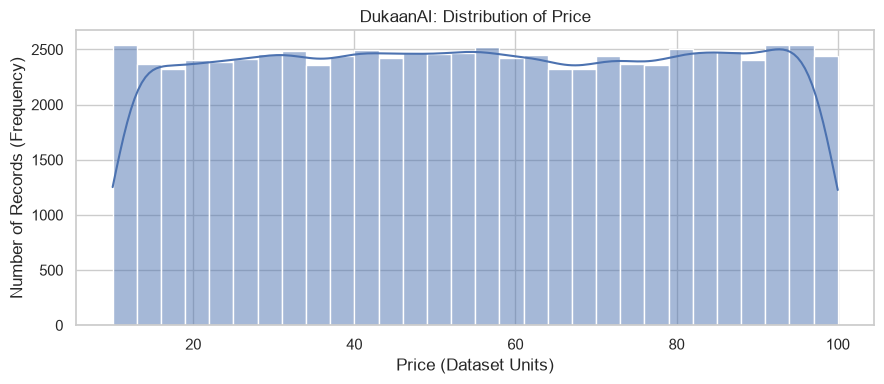

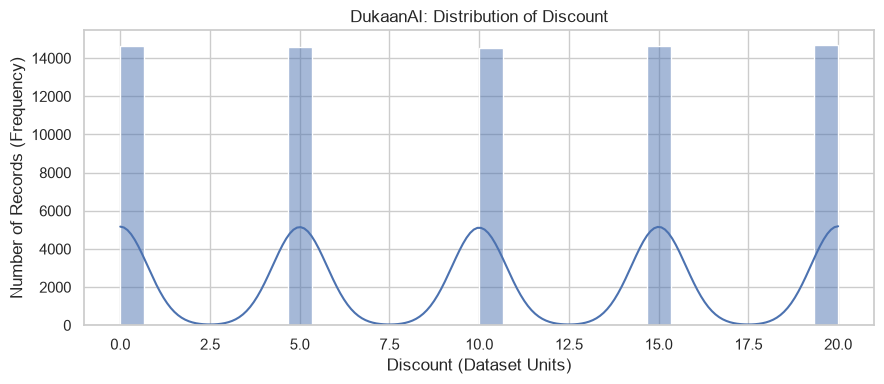

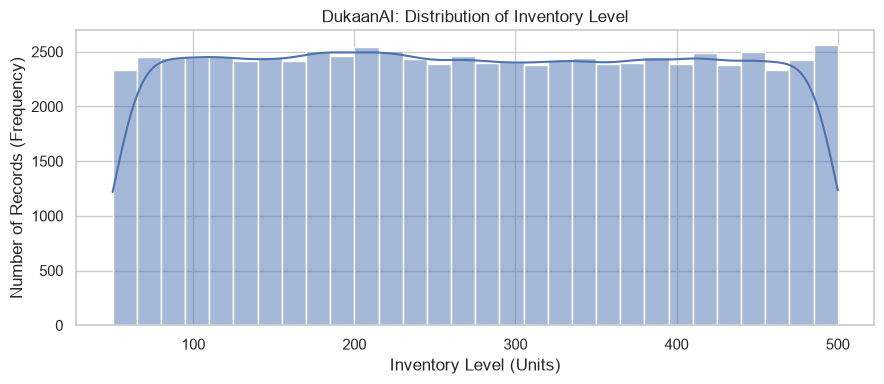

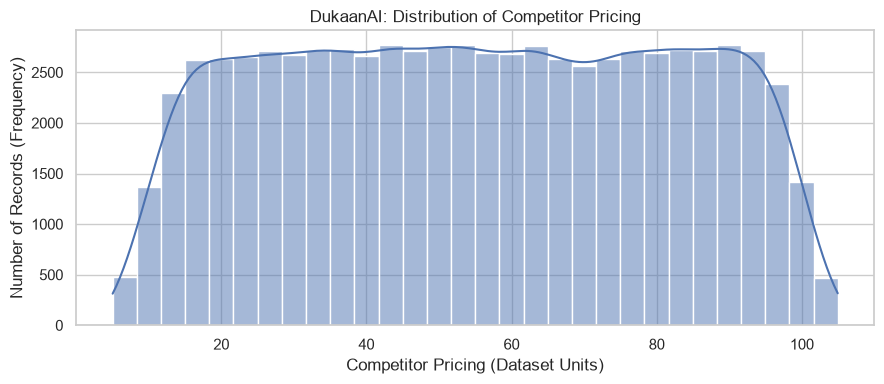

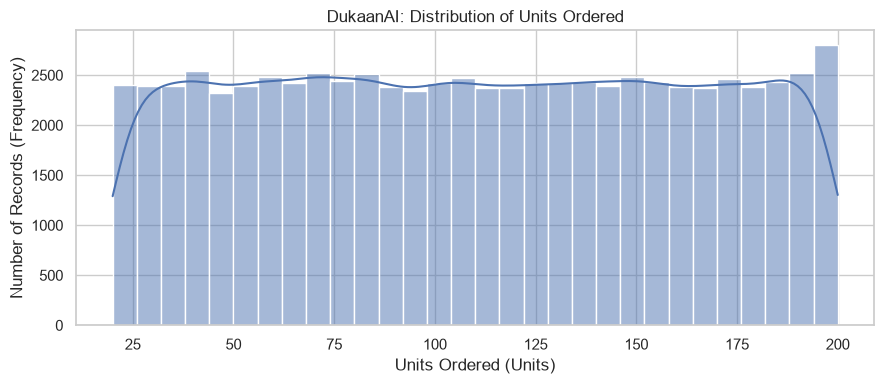

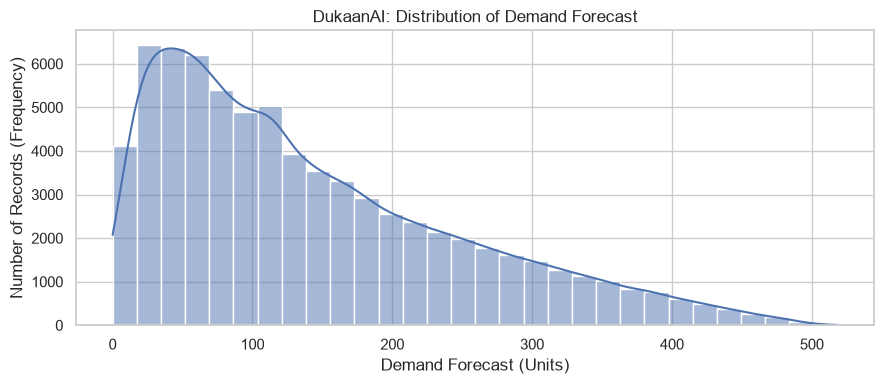

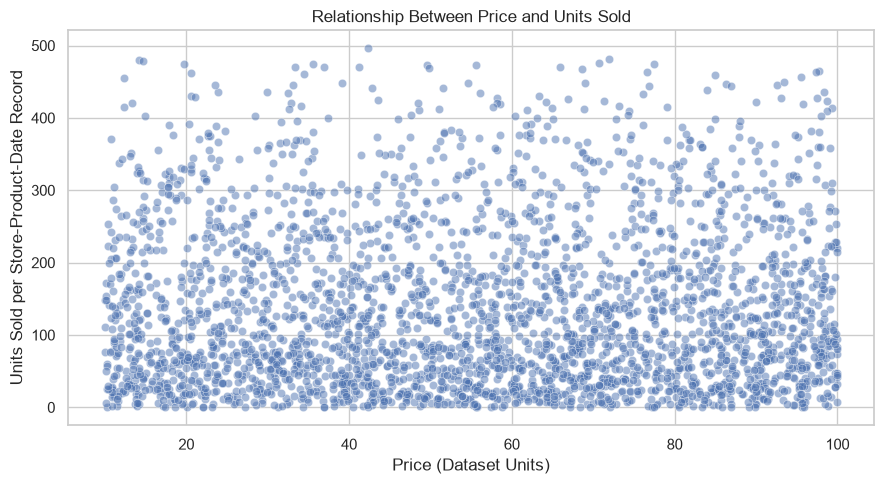

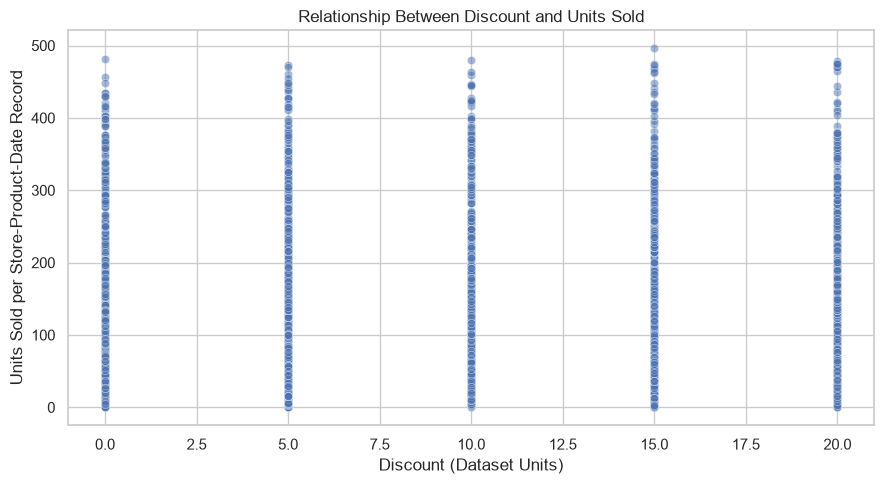

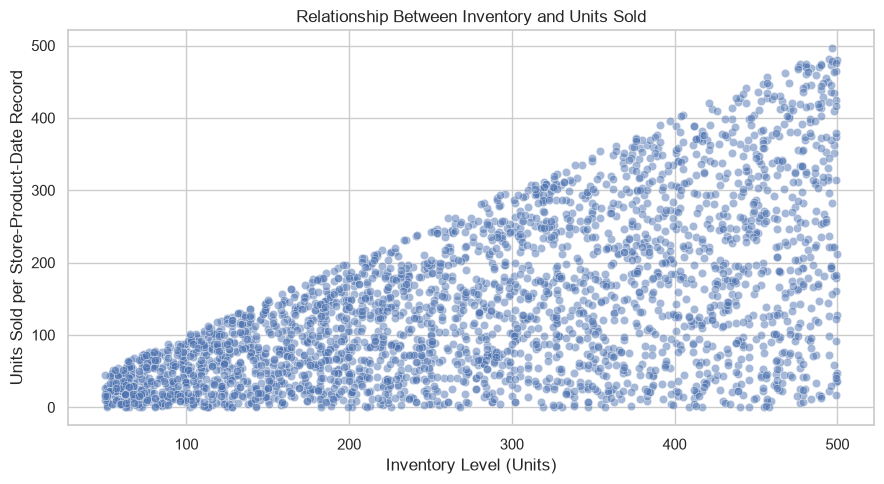

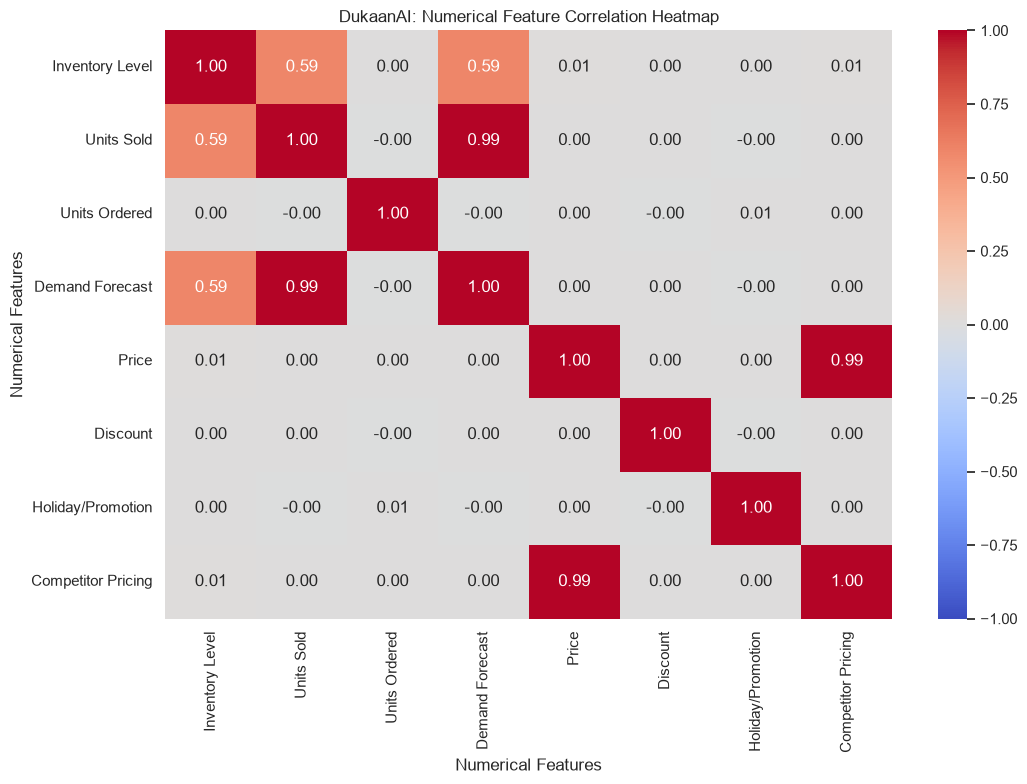


Numerical summary for business analysis:


,count,mean,std,min,25%,50%,75%,max
Price,73100.0,55.135108,26.021945,10.00,32.65,55.05,77.8600,100.00
Discount,73100.0,10.009508,7.083746,0.00,5.00,10.00,15.0000,20.00
Inventory Level,73100.0,274.469877,129.949514,50.00,162.00,273.00,387.0000,500.00
Units Sold,73100.0,136.464870,108.919406,0.00,49.00,107.00,203.0000,499.00
Units Ordered,73100.0,110.004473,52.277448,20.00,65.00,110.00,155.0000,200.00
Demand Forecast,73100.0,142.582418,108.387595,0.01,55.48,114.45,208.0525,518.55


In [10]:
print("\n" + "=" * 65)
print("SECTION 7: PRICE, DISCOUNT AND INVENTORY ANALYSIS")
print("=" * 65)

distribution_cols = [
    "Price",
    "Discount",
    "Inventory Level",
    "Competitor Pricing",
    "Units Ordered",
    "Demand Forecast"
]

distribution_labels = {
    "Price": (
        "Price (Dataset Units)",
        "Number of Records (Frequency)"
    ),
    "Discount": (
        "Discount (Dataset Units)",
        "Number of Records (Frequency)"
    ),
    "Inventory Level": (
        "Inventory Level (Units)",
        "Number of Records (Frequency)"
    ),
    "Competitor Pricing": (
        "Competitor Pricing (Dataset Units)",
        "Number of Records (Frequency)"
    ),
    "Units Ordered": (
        "Units Ordered (Units)",
        "Number of Records (Frequency)"
    ),
    "Demand Forecast": (
        "Demand Forecast (Units)",
        "Number of Records (Frequency)"
    )
}

for col in distribution_cols:
    plt.figure(figsize=(9, 4))
    sns.histplot(
        data=eda_df,
        x=col,
        bins=30,
        kde=True
    )
    x_label, y_label = distribution_labels[col]
    plt.title(f"DukaanAI: Distribution of {col}")
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.tight_layout()
    plt.show()

price_sample = eda_df.sample(
    n=min(3000, len(eda_df)),
    random_state=42
)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=price_sample,
    x="Price",
    y="Units Sold",
    alpha=0.5
)
plt.title("Relationship Between Price and Units Sold")
plt.xlabel("Price (Dataset Units)")
plt.ylabel("Units Sold per Store-Product-Date Record")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=price_sample,
    x="Discount",
    y="Units Sold",
    alpha=0.5
)
plt.title("Relationship Between Discount and Units Sold")
plt.xlabel("Discount (Dataset Units)")
plt.ylabel("Units Sold per Store-Product-Date Record")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=price_sample,
    x="Inventory Level",
    y="Units Sold",
    alpha=0.5
)
plt.title("Relationship Between Inventory and Units Sold")
plt.xlabel("Inventory Level (Units)")
plt.ylabel("Units Sold per Store-Product-Date Record")
plt.tight_layout()
plt.show()

correlation_cols = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "Price",
    "Discount",
    "Holiday/Promotion",
    "Competitor Pricing"
]

correlation_matrix = eda_df[
    correlation_cols
].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("DukaanAI: Numerical Feature Correlation Heatmap")
plt.xlabel("Numerical Features")
plt.ylabel("Numerical Features")
plt.tight_layout()
plt.show()

print("\nNumerical summary for business analysis:")
display(
    eda_df[
        [
            "Price",
            "Discount",
            "Inventory Level",
            "Units Sold",
            "Units Ordered",
            "Demand Forecast"
        ]
    ].describe().T
)


In [11]:
print("\n" + "=" * 65)
print("SECTION 8: SAVE OUTPUTS")
print("=" * 65)

eda_df.to_csv(
    "dukaanai_cleaned_dataset.csv",
    index=False
)

train_df.to_csv(
    "dukaanai_train.csv",
    index=False
)

validation_df.to_csv(
    "dukaanai_validation.csv",
    index=False
)

test_df.to_csv(
    "dukaanai_test.csv",
    index=False
)

print("Saved: dukaanai_cleaned_dataset.csv")
print("Saved: dukaanai_train.csv")
print("Saved: dukaanai_validation.csv")
print("Saved: dukaanai_test.csv")

print("\n" + "=" * 65)
print("DUKAANAI: INITIAL BUSINESS FINDINGS")
print("=" * 65)

print("Total records after cleaning:", len(eda_df))
print("Unique stores:", eda_df["Store ID"].nunique())
print("Unique products:", eda_df["Product ID"].nunique())
print(
    "Date range:",
    eda_df["Date"].min().date(),
    "to",
    eda_df["Date"].max().date()
)

print(
    "Average units sold per record:",
    round(eda_df["Units Sold"].mean(), 2)
)

print(
    "Median units sold per record:",
    round(eda_df["Units Sold"].median(), 2)
)

print(
    "Category with highest total units sold:",
    category_sales["sum"].idxmax()
)

print(
    "Product with highest total units sold:",
    product_sales["sum"].idxmax()
)

print(
    "Store with highest total units sold:",
    store_sales["sum"].idxmax()
)

print(
    "Date with highest total sales:",
    daily_sales.idxmax().date()
)

print("Highest daily units sold:", daily_sales.max())

print("\nEDA workflow completed.")



SECTION 8: SAVE OUTPUTS
Saved: dukaanai_cleaned_dataset.csv
Saved: dukaanai_train.csv
Saved: dukaanai_validation.csv
Saved: dukaanai_test.csv

DUKAANAI: INITIAL BUSINESS FINDINGS
Total records after cleaning: 73100
Unique stores: 5
Unique products: 20
Date range: 2022-01-01 to 2024-01-01
Average units sold per record: 136.46
Median units sold per record: 107.0
Category with highest total units sold: Furniture
Product with highest total units sold: P0016
Store with highest total units sold: S003
Date with highest total sales: 2022-06-21
Highest daily units sold: 17239.0

EDA workflow completed.
